In [23]:
%matplotlib inline 

In [24]:
import os
import io
import re
import itertools
import numpy as np
import pandas as pd
import json

In [25]:
data_sources = ['mnd_TSC']

distr_dims = ['-'.join(['Distancegroup', 'Timeperiodseq']),
              '-'.join(['Distancegroup', 'Legs'])]

aggr_levels = ['lsoa']
sample_sizes = ['sample_perc_10']

export = True
out_folder = r'./outputs'
tolerance = 0.01

run_info = list(itertools.product(data_sources, distr_dims, aggr_levels, sample_sizes))

In [26]:
def prepare_results_filepaths(run_results_fldr):
    flpaths = dict()
    flpaths['od'] = os.path.join(run_results_fldr, 'od_filtered.csv')
    flpaths['trs_obs_descr'] = os.path.join(run_results_fldr, 'trs_obs_descr.csv')
    flpaths['trs_obs_info'] = os.path.join(run_results_fldr, 'trs_obs_info.csv')
    flpaths['trs_mdl_descr'] = os.path.join(run_results_fldr, 'trs_mdl_descr.csv')
    flpaths['trs_mdl_info'] = os.path.join(run_results_fldr, 'trs_mdl_info.csv')
    flpaths['observed_distribution'] = os.path.join(run_results_fldr, 'target_distribution.csv')
    flpaths['optimisation_results'] = os.path.join(run_results_fldr, 'results.json')
    flpaths['trs_descr_comp'] = os.path.join(run_results_fldr, 'trs_descr_comp.csv')
    return flpaths

In [27]:
def prepare_od_from_tours(trs_info, trs_descr, od_dims, name='Trips'):
    times_used = trs_info['Timesused']
    trs_descr = trs_descr.join(times_used)
    od = trs_descr.groupby(od_dims)['Timesused'].sum()
    od.name = name
    return od

In [28]:
def prepare_od_comparison(od_mdl, od_obs):
    od_obs.name = 'ObservedTrips'
    comp = od_obs.to_frame().join(od_mdl)
    comp.columns.name = 'TripsSource'
    comp = comp.stack()
    comp.name = 'Trips'
    return comp

In [29]:
def get_input_params_from_folder(infldr):
    fldrs = [name for name in os.listdir(infldr) if os.path.isdir(os.path.join(infldr, name))]
    inputs = []
    for fldr in fldrs:
        matches = re.findall('(\d+)legs-over(\d+)trips-distrConstr(\w+)', fldr)
        if matches:
            legs = int(matches[0][0])
            trips = int(matches[0][1])
            if matches[0][2] == 'True':
                distr_constr_enabled = True
            elif matches[0][2] == 'False':
                distr_constr_enabled = False
            else:
                raise ValueError('distrConstrEnabled must be either True or False')
                
            inputs.append([legs, trips, distr_constr_enabled])
        
    return inputs

In [30]:
def prepare_distribution_comparison(trs_mdl_info, obs_distr):
    
    obs_distr.drop(columns=['Size'], inplace=True)

    optim_distr = trs_mdl_info.groupby('Distrgroupid')['Timesused'].sum()
    optim_distr = optim_distr.div(optim_distr.sum())
    optim_distr.name = 'Percentage'
    
    # We need to identify the distribution dimensions cols (should be all apart form the Percentage)
    idx_cols = list()
    for c in obs_distr.columns:
        if c != 'Percentage':
            idx_cols.append(c)
    
    obs_distr.set_index(idx_cols, append=True).squeeze()
    
    distr_comp = obs_distr['Percentage'].to_frame().join(optim_distr, rsuffix='_')
    distr_comp.columns = ['obs', 'mdl']
    distr_comp.columns.name = 'Type'
    distr_comp = distr_comp.stack('Type')
    distr_comp.name = 'Percentage'

    return distr_comp

In [31]:
def collapse_tour_legs(trs, leg_descr_cols, idx_cols=['Tourid']):
    seqs = list()
    for c in leg_descr_cols:
        seq = trs.groupby(level=idx_cols)[c].apply(tuple)
        seqs.append(seq)
    
    trs_collapsed = pd.concat(seqs, axis=1)
    
    return trs_collapsed

In [32]:
def include_run_info(df, d_run_params):
    try:
        df = df.to_frame()
    except AttributeError:
        pass
    
    for k, v in d_run_params.items():
        df[k] = v
        
    df.set_index(list(d_run_params.keys()), append=True, inplace=True)
    df = df.squeeze()
    return df

In [78]:
def compare_times_used(comp_descr, trs_obs_info, trs_mdl_info,
                       leg_descr_cols, idx_cols):
    
    trs_obs_info['Type'] = 'obs'
    trs_mdl_info['Type'] = 'mdl'
    
    trs_obs_info.set_index('Type', append=True, inplace=True)
    trs_mdl_info.set_index('Type', append=True, inplace=True)
    trs_obs_info = trs_obs_info.swaplevel()
    trs_mdl_info = trs_mdl_info.swaplevel()
    
    times_used = pd.concat([trs_obs_info['Timesused'], 
                            trs_mdl_info['Timesused']])

    df = collapse_tour_legs(comp_descr, leg_descr_cols, idx_cols)
    df = df.join(times_used)
    
    obs = df.xs('obs', level='Type', drop_level=False)
    mdl = df.xs('mdl', level='Type', drop_level=False)
    
    obs = obs.groupby(leg_descr_cols)['Timesused'].sum()
    mdl = mdl.groupby(leg_descr_cols)['Timesused'].sum()
    
    mrg = pd.merge(obs.to_frame(), mdl.to_frame(),
                   left_index=True, right_index=True,
                   how='outer',
                   suffixes=('_obs', '_mdl')).fillna(0)

    mrg.columns.name = 'Type'
    mrg.rename(columns=lambda x: x.replace('Timesused_', ''), inplace=True)
    mrg = mrg.stack()
    mrg.name = 'Timesused'

    df = mrg.unstack()
    df['Diff'] = df['obs'] - df['mdl']
    df['Diffabs'] = df['Diff'].abs()
    comp_times_used = df
    
    return comp_times_used

In [79]:
def prepare_run_info_dict(run_params):
    (data_source, distr_dims, aggr_level, sample_size,
     legs, trips_thresh, distr_constr_enabled) = run_params
    
    d_run_params = dict()
    d_run_params['DataSource'] = data_source
    d_run_params['AggrLevel'] = aggr_level
    d_run_params['SampleSize'] = sample_size
    d_run_params['DistrDims'] = distr_dims
    d_run_params['MaxLegs'] = int(legs)
    d_run_params['TripsThresh'] = int(trips_thresh)
    d_run_params['DistrConstr'] = distr_constr_enabled
    return d_run_params

In [80]:
def main(model_info):

    data_source, distr_dims, aggr_level, sample_size = model_info
    
    results_folder = r'../outputs/{}/{}/{}/{}'.format(data_source, distr_dims, aggr_level, sample_size)
    params = get_input_params_from_folder(results_folder)

    concat_od_mdl = list()
    concat_od_obs = list()

    concat_trs_mdl_used_descr = list()

    concat_comp_distrs = list()
    concat_comp_descrs = list()
    concat_comp_times_used = list()
    
    for legs, trips_thresh, distr_constr_enabled in params:
        print(aggr_level)
        print(legs, trips_thresh, distr_constr_enabled)
        run_info = model_info.copy()
        
        run_tmplt = '{}legs-over{}trips-distrConstr{}'.format(legs, trips_thresh, distr_constr_enabled)
        run_results_fldr = os.path.join(results_folder, run_tmplt)

        flpaths = prepare_results_filepaths(run_results_fldr)
        
        obs_distr = pd.read_csv(flpaths['observed_distribution'], index_col='Distrgroupid')

        trs_obs_info = pd.read_csv(flpaths['trs_obs_info'], index_col=['Tourid'])
        trs_obs_descr = pd.read_csv(flpaths['trs_obs_descr'], index_col=['Tourid', 'Legidx'])
    
        trs_mdl_info = pd.read_csv(flpaths['trs_mdl_info'], index_col=['Tourid'])
        trs_mdl_descr = pd.read_csv(flpaths['trs_mdl_descr'], index_col=['Tourid', 'Legidx'])
    
        od_dims = ['Source', 'Target', 'Purpose', 'Direction', 'Timeperiod']
        
        # For the observed tours prepare the od only for the high frequency tours
        # trs_obs_info['Timesused'] = np.where(trs_obs_info['Inlowfreqgroup'], 0, 1)
        
        od_obs = prepare_od_from_tours(trs_obs_info, trs_obs_descr,
                                       od_dims=od_dims, name='ObservedTrips')
        
        od_mdl = prepare_od_from_tours(trs_mdl_info, trs_mdl_descr,
                                       od_dims=od_dims, name='ModelledTrips')
        
        if od_mdl is None:
            print('No results for legs:{}-trips:{}-distrConstr:{}'.format(legs, trips_thresh, distr_constr_enabled))
            continue

        comp_distr = prepare_distribution_comparison(trs_mdl_info, obs_distr)

        #comp_descr = prepare_descr_comparison(trs_obs_descr, trs_mdl_descr,
        #                                      trs_mdl_info.Timesused, True)

        usecols = ['Type', 'Tourid', 'Legidx',
                   'Source', 'Target', 'Purpose', 'Direction', 'Timeperiod',
                   'Inboth', 'Inlowfreqgroup']
        
        comp_descr = pd.read_csv(flpaths['trs_descr_comp'],
                                 usecols=usecols,
                                 index_col=['Type', 'Tourid', 'Legidx'])
        
        leg_descr_cols = ['Source', 'Timeperiod']
        idx_cols = ['Type', 'Tourid']
        comp_times_used = compare_times_used(comp_descr,
                                             trs_obs_info, trs_mdl_info,
                                             leg_descr_cols, idx_cols)
        
        run_info.extend([legs, trips_thresh, distr_constr_enabled])
        d_run_info = prepare_run_info_dict(run_info)
        
        od_obs = include_run_info(od_obs, d_run_info)
        od_mdl = include_run_info(od_mdl, d_run_info)
        comp_distr = include_run_info(comp_distr, d_run_info)
        comp_descr = include_run_info(comp_descr, d_run_info)
        comp_times_used = include_run_info(comp_times_used, d_run_info)
        
        concat_od_mdl.append(od_mdl)
        concat_od_obs.append(od_obs)
        concat_comp_descrs.append(comp_descr)
        concat_comp_distrs.append(comp_distr)
        concat_comp_times_used.append(comp_times_used)

    od_mdl = pd.concat(concat_od_mdl)
    od_obs = pd.concat(concat_od_obs)

    comp_ods = prepare_od_comparison(od_mdl, od_obs)
    comp_distrs = pd.concat(concat_comp_distrs)
    comp_descrs = pd.concat(concat_comp_descrs)
    comp_times_used = pd.concat(concat_comp_times_used)
    
    return comp_ods, comp_distrs, comp_descrs, comp_times_used

In [81]:
comparisons = dict()

ods = list()
distrs = list()
descrs = list()
times_used = list()

for ri in run_info:
    comp_ods, comp_distrs, comp_descrs, comp_times_used = main(list(ri))
    ods.append(comp_ods)
    distrs.append(comp_distrs)
    descrs.append(comp_descrs)
    times_used.append(comp_times_used)

comparisons['ods'] = pd.concat(ods)
comparisons['distrs'] = pd.concat(distrs)
comparisons['descrs'] = pd.concat(descrs)
comparisons['timesused'] = pd.concat(times_used)

if export:
    #mdl_nchains.to_csv(os.path.join(out_folder, 'optimisation_results.csv'), header=True, index=True)
    comparisons['ods'].to_csv(os.path.join(out_folder, 'comparison_od.csv'), header=True)
    comparisons['distrs'].to_csv(os.path.join(out_folder, 'comparison_distributions.csv'), header=True, index=True)
    comparisons['descrs'].to_csv(os.path.join(out_folder, 'comparison_descrs.csv'), header=True, index=True)
    comparisons['timesused'].to_csv(os.path.join(out_folder, 'comparison_times_used.csv'), header=True, index=True)

lsoa
5 1 False
lsoa
5 1 True
lsoa
5 1 False
lsoa
5 1 True


In [82]:
df = comparisons['distrs'].copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Type')
df['Diff_perc'] = df['obs'].sub(df['mdl'])

df['BelowTolerance'] = df.Diff_perc.abs() <= tolerance
df.dropna(inplace=True)
df['BelowTolerance'].all()

True

In [83]:
grpby_lvls = ['DataSource', 'DistrDims', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr',
              'TripsSource', 'Purpose']

df = comparisons['ods'].groupby(level=grpby_lvls).sum()

df = df.unstack('TripsSource')

df['Diff'] = df.ObservedTrips - df.ModelledTrips
df['Diff_perc'] = df.ModelledTrips/df.ObservedTrips - 1

df.style.format({
    'ModelledTrips': '{:,.0f}'.format,
    'ObservedTrips': '{:,.0f}'.format,
    'Diff': '{:,.0f}'.format,
    'Diff_perc': '{:.0%}'.format
})

In [84]:
filters = dict()
filters['DataSource'] = 'mnd_TSC'
filters['DistrDims'] = 'Distancegroup-Timeperiodseq'
filters['AggrLevel'] = 'lsoa'
filters['SampleSize'] = 'sample_perc_10'
filters['MaxLegs'] = 5
filters['TripsThresh'] = 1
filters['DistrConstr'] = True

In [85]:
if filters:
    comparisons_filt = dict()
    for k, f in comparisons.items():
        comparisons_filt[k] = comparisons[k].xs(list(filters.values()),
                                                level=list(filters.keys()))
    analysis_comp = comparisons_filt.copy()
else:
    analysis_comp = comparisons.copy()

grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr']

grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]

dfg = analysis_comp['distrs'].groupby(level=grpby_lvls)
for k, g in dfg:
    print(k)
    plt = g.unstack('Type')
    plt.plot(kind='bar')

In [86]:
df = analysis_comp['timesused'].copy()
df

Type                                                                     obs  \
Source                                             Timeperiod                  
(E01014387, E01014377, E01014474)                  (IP, IP, IP)          1.0   
(E01014387, E01014379)                             (AM, PM)              1.0   
(E01014387, E01014410)                             (PM, OP)              1.0   
(E01014387, E01014427, E01014370)                  (AM, IP, OP)          1.0   
                                                   (AM, PM, OP)          0.0   
(E01014387, E01014470)                             (AM, AM)              1.0   
(E01014387, E01014531)                             (AM, PM)              1.0   
(E01014387, E01014556)                             (PM, OP)              1.0   
(E01014387, E01014994, E01014949)                  (AM, IP, PM)          1.0   
(E01014387, E01033345, E01014395)                  (IP, IP, IP)          1.0   
(E01014396, E01014370, E01014403, E01014526)       (AM, PM, OP, OP)      0.0   
(E01014396, E01014370, E01014542, E01014531)       (AM, IP, IP, OP)      1.0   
(E01014396, E01014388, E01014370)                  (AM, AM, IP)          1.0   
                                                   (AM, PM, PM)          0.0   
(E01014396, E01014392, E01033358, E01014370)       (AM, AM, IP, PM)      1.0   
(E01014396, E01014392, E01033358, E01014542)       (AM, AM, PM, PM)      0.0   
(E01014396, E01014403)                             (AM, PM)              1.0   
(E01014396, E01014407)                             (IP, OP)              1.0   
(E01014396, E01014474, E01014379)                  (AM, AM, OP)          1.0   
(E01014396, E01014526)                             (IP, PM)              1.0   
(E01014396, E01014539)                             (IP, IP)              1.0   
(E01014396, E01014542)                             (PM, PM)              1.0   
(E01014396, E01014542, E01014531)                  (PM, OP, OP)          0.0   
(E01014396, E01014712, E01014498)                  (IP, PM, OP)          1.0   
(E01014396, E01014727, E01014916)                  (AM, IP, PM)          1.0   
(E01014396, E01014885)                             (AM, IP)              1.0   
(E01014396, E01014926, E01014938, E01014427)       (AM, IP, IP, IP)      1.0   
(E01014396, E01014943)                             (IP, IP)              1.0   
(E01014396, E01014948, E01014925)                  (IP, IP, IP)          1.0   
(E01014396, E01014972)                             (IP, IP)              1.0   
...                                                                      ...   
(E01033350, E01033331, E01014664)                  (AM, PM, PM)          1.0   
(E01033355, E01014897, E01014972)                  (AM, PM, PM)          1.0   
(E01033356, E01014572)                             (OP, OP)              1.0   
(E01033356, E01014585)                             (AM, PM)              1.0   
(E01033356, E01033345)                             (AM, IP)              1.0   
(E01033356, E01033347, E01014500)                  (IP, PM, PM)          1.0   
(E01033358, E01014526)                             (IP, IP)              1.0   
(E01033358, E01014542)                             (IP, PM)              1.0   
(E01033358, E01014572)                             (AM, AM)              1.0   
(E01033358, E01014646, E01014966)                  (IP, PM, OP)          1.0   
(E01033358, E01014899, E01014617)                  (AM, IP, IP)          1.0   
(E01033358, E01014906)                             (AM, PM)              0.0   
                                                   (IP, PM)              1.0   
(E01033358, E01014906, E01014924)                  (AM, IP, PM)          1.0   
                                                   (IP, IP, PM)          0.0   
(E01033358, E01033331)                             (AM, IP)              1.0   
(E01033366, E01014582)                             (PM, OP)              1.0   


In [87]:
df.Diff.describe()

count    3332.000000
mean        0.082233
std         0.538371
min        -1.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: Diff, dtype: float64

In [88]:
grpby_lvls = ['MaxLegs', 'TripsThresh', 'DistrConstr', 'Inboth']
grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]
analysis_comp['descrs'].groupby(grpby_lvls).size().unstack('DistrConstr')

AttributeError: 'Index' object has no attribute 'remove_unused_levels'

In [93]:
grpby_cols = ['DataSource', 'AggrLevel', 'SampleSize',
              'DistrDims', 'MaxLegs', 'TripsThresh']#, 'DistrConstr']

comparisons['timesused'].xs(True, level='DistrConstr').groupby(level=grpby_cols).sum()

Type                                                                                    obs  \
DataSource AggrLevel SampleSize     DistrDims                   MaxLegs TripsThresh           
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs          5       1            2975.0   
                                    Distancegroup-Timeperiodseq 5       1            2975.0   

Type                                                                                    mdl  \
DataSource AggrLevel SampleSize     DistrDims                   MaxLegs TripsThresh           
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs          5       1            2717.0   
                                    Distancegroup-Timeperiodseq 5       1            2701.0   

Type                                                                                  Diff  \
DataSource AggrLevel SampleSize     DistrDims                   MaxLegs TripsThresh          
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs          5       1            258.0   
                                    Distancegroup-Timeperiodseq 5       1            274.0   

Type                                                                                 Diffabs  
DataSource AggrLevel SampleSize     DistrDims                   MaxLegs TripsThresh           
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs          5       1              946.0  
                                    Distancegroup-Timeperiodseq 5       1              988.0

In [99]:
df = comparisons['timesused'].copy()
#df = df[df.Diffabs!=0]
df

,,,,,,,,Type,obs,mdl,Diff,Diffabs
Source,Timeperiod,DataSource,AggrLevel,SampleSize,DistrDims,MaxLegs,TripsThresh,DistrConstr,,,,
"(E01014387, E01014377, E01014474)","(IP, IP, IP)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1.0,1.0,0.0,0.0
"(E01014387, E01014379)","(AM, PM)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1.0,1.0,0.0,0.0
"(E01014387, E01014410)","(PM, OP)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1.0,1.0,0.0,0.0
"(E01014387, E01014427, E01014370)","(AM, IP, OP)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1.0,1.0,0.0,0.0
"(E01014387, E01014470)","(AM, AM)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1.0,1.0,0.0,0.0
"(E01014387, E01014531)","(AM, PM)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1.0,1.0,0.0,0.0
"(E01014387, E01014556)","(PM, OP)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1.0,1.0,0.0,0.0
"(E01014387, E01014994, E01014949)","(AM, IP, PM)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1.0,1.0,0.0,0.0
"(E01014387, E01033345, E01014395)","(IP, IP, IP)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1.0,1.0,0.0,0.0


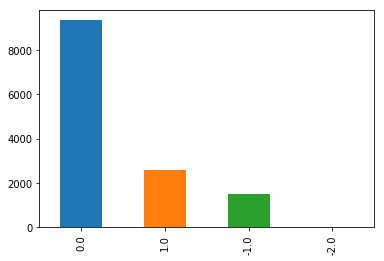

In [100]:
df.Diff.value_counts().plot('bar')

In [101]:
analysis_comp['descrs']

Source     Target Purpose     Direction Timeperiod  \
Type Tourid Legidx                                                          
mdl  89     0       E01014405  E01033353      HB      FromHome         AM   
            1       E01033353  E01014405      HB        ToHome         OP   
     98     0       E01014405  E01033353      HB      FromHome         IP   
            1       E01033353  E01014370     NHB  NonHomeBased         PM   
            2       E01014370  E01014405      HB        ToHome         OP   
     125    0       E01014405  E01014370      HB      FromHome         IP   
            1       E01014370  E01014405      HB        ToHome         IP   
     126    0       E01014405  E01014370      HB      FromHome         IP   
            1       E01014370  E01014405      HB        ToHome         OP   
     203    0       E01014387  E01033345      HB      FromHome         IP   
            1       E01033345  E01014395     NHB  NonHomeBased         IP   
            2       E01014395  E01014387      HB        ToHome         IP   
     265    0       E01014387  E01014994      HB      FromHome         AM   
            1       E01014994  E01014949     NHB  NonHomeBased         IP   
            2       E01014949  E01014387      HB        ToHome         PM   
     315    0       E01014387  E01014556      HB      FromHome         PM   
            1       E01014556  E01014387      HB        ToHome         OP   
     337    0       E01014387  E01014531      HB      FromHome         AM   
            1       E01014531  E01014387      HB        ToHome         PM   
     343    0       E01014387  E01014470      HB      FromHome         AM   
            1       E01014470  E01014387      HB        ToHome         AM   
     385    0       E01014387  E01014427      HB      FromHome         AM   
            1       E01014427  E01014370     NHB  NonHomeBased         PM   
            2       E01014370  E01014387      HB        ToHome         OP   
     395    0       E01014387  E01014410      HB      FromHome         PM   
            1       E01014410  E01014387      HB        ToHome         OP   
     410    0       E01014387  E01014379      HB      FromHome         AM   
            1       E01014379  E01014387      HB        ToHome         PM   
     417    0       E01014387  E01014377      HB      FromHome         IP   
            1       E01014377  E01014474     NHB  NonHomeBased         IP   
...                       ...        ...     ...           ...        ...   
obs  567606 1       E01014560  E01014763      HB        ToHome         IP   
     567979 0       E01014708  E01014412      HB      FromHome         IP   
            1       E01014412  E01014865     NHB  NonHomeBased         IP   
            2       E01014865  E01014708      HB        ToHome         PM   
     568628 0       E01014423  E01014370      HB      FromHome         AM   
            1       E01014370  E01014379     NHB  NonHomeBased         IP   
            2       E01014379  E01014423      HB        ToHome         OP   
     568666 0       E01014526  E01014588      HB      FromHome         AM   
            1       E01014588  E01015010     NHB  NonHomeBased         PM   
            2       E01015010  E01014523     NHB  NonHomeBased         PM   
            3       E01014523  E01014526      HB        ToHome         OP   
     568835 0       E01014730  E01014401      HB      FromHome         AM   
            1       E01014401  E01014730      HB        ToHome         PM   
     568959 0       E01014459  E01014429      HB      FromHome         AM   
            1       E01014429  E01014395     NHB  NonHomeBased         AM   
            2       E01014395  E01014459      HB        ToHome         IP   
     569124 0       E01014532  E01033350      HB      FromHome         IP   
            1       E01033350  E01014532      HB        ToHome         OP   
     569572 0       E01014860  E01014861      HB      FromHome         AM   
            1      